In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA, ARIMA


# SARIMA no comércio varejista brasileiro

## Análise de Minas Gerais

**Fonte dos dados:** Pesquisa Mensal do Comércio (PMC/IBGE)  
**Indicador:** Índice de volume de vendas do comércio varejista ampliado  
**Base:** 2022 = 100, sem ajuste sazonal

### Objetivo

Analisar a série mensal de vendas de Minas Gerais, identificar tendências e padrões sazonais, ajustar um modelo SARIMA e produzir previsões para os próximos 24 meses.

In [3]:
pmc = pd.read_csv(
    "https://github.com/padsInsper/202634-fa/releases/download/data/pmc_volume_uf.csv"
)

MINHA_UF = "Minas Gerais"

df_sf = (
    pmc.query("uf == @MINHA_UF")
    .rename(columns={"uf": "unique_id", "data": "ds", "volume_idx": "y"})
    [["unique_id", "ds", "y"]]
    .reset_index(drop=True)
)

df_sf.head()

,unique_id,ds,y
0,Minas Gerais,2004-01-01,47.04283
1,Minas Gerais,2004-02-01,43.47343
2,Minas Gerais,2004-03-01,49.05633
3,Minas Gerais,2004-04-01,48.69024
4,Minas Gerais,2004-05-01,49.33090


## 1. Análise descritiva

### Série histórica

O gráfico da série ao longo do tempo ajuda a observar tendências e possíveis padrões que se repetem durante o ano.

Número de observações: 266
Período: 2004-01-01 00:00:00 a 2026-02-01 00:00:00
Valores ausentes: 0


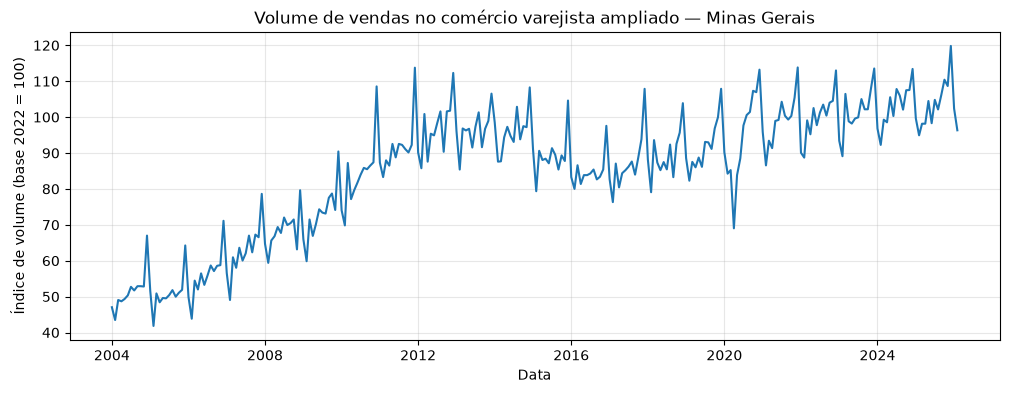

In [4]:
df_sf["ds"] = pd.to_datetime(df_sf["ds"])

print("Número de observações:", len(df_sf))
print("Período:", df_sf["ds"].min(), "a", df_sf["ds"].max())
print("Valores ausentes:", df_sf["y"].isna().sum())

plt.figure(figsize=(12, 4))
plt.plot(df_sf["ds"], df_sf["y"])
plt.title("Volume de vendas no comércio varejista ampliado — Minas Gerais")
plt.xlabel("Data")
plt.ylabel("Índice de volume (base 2022 = 100)")
plt.grid(True, alpha=0.3)
plt.show()

**Observação inicial:** a série apresenta uma tendência geral de crescimento no período, com oscilações e uma queda acentuada em 2020. O gráfico de linha, sozinho, não permite confirmar um padrão sazonal; vou investigar isso com a ACF e a PACF.

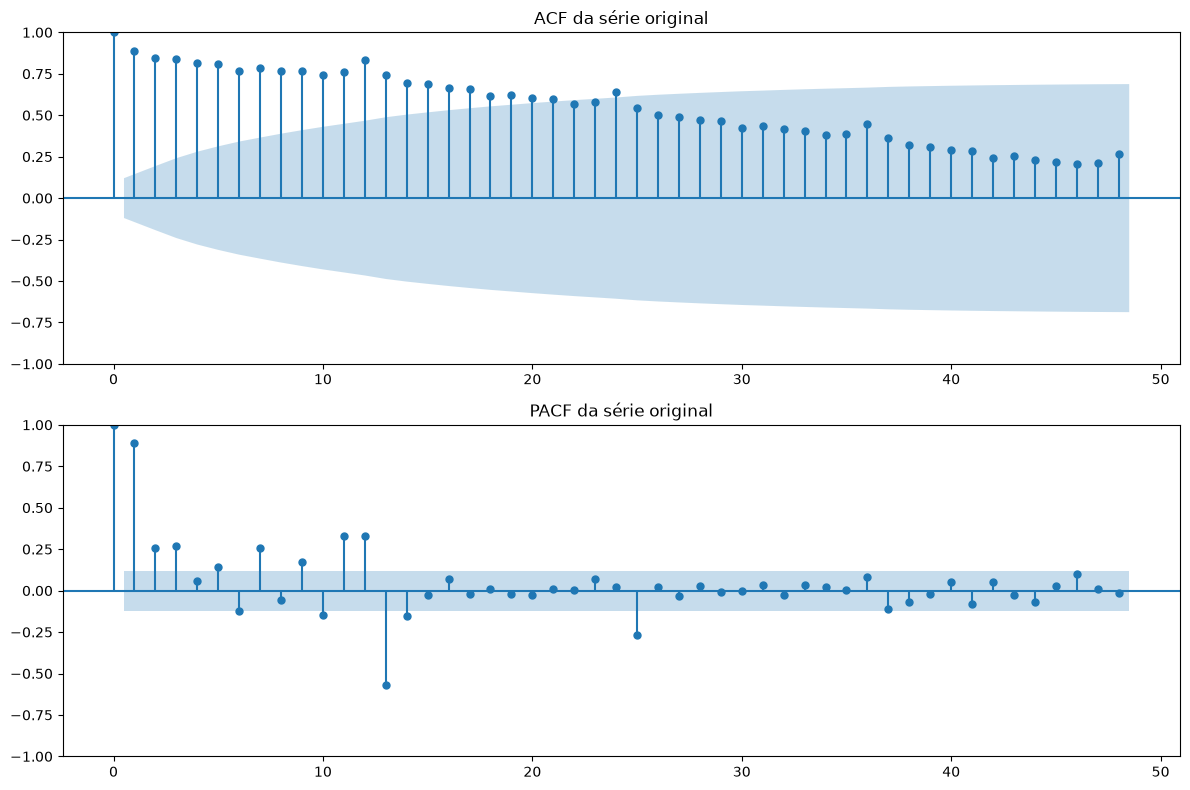

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(df_sf["y"], lags=48, ax=axes[0])
axes[0].set_title("ACF da série original")

plot_pacf(df_sf["y"], lags=48, method="ywm", ax=axes[1])
axes[1].set_title("PACF da série original")

plt.tight_layout()
plt.show()

**ACF e PACF:** a ACF da série original diminui lentamente, o que sugere tendência ou forte persistência. Valores elevados próximos aos lags 12 e 24 podem indicar sazonalidade anual. A PACF apresenta um pico forte no lag 1 e outros na região dos lags sazonais. Como a série original ainda pode não ser estacionária, esses padrões serão reavaliados após a diferenciação.

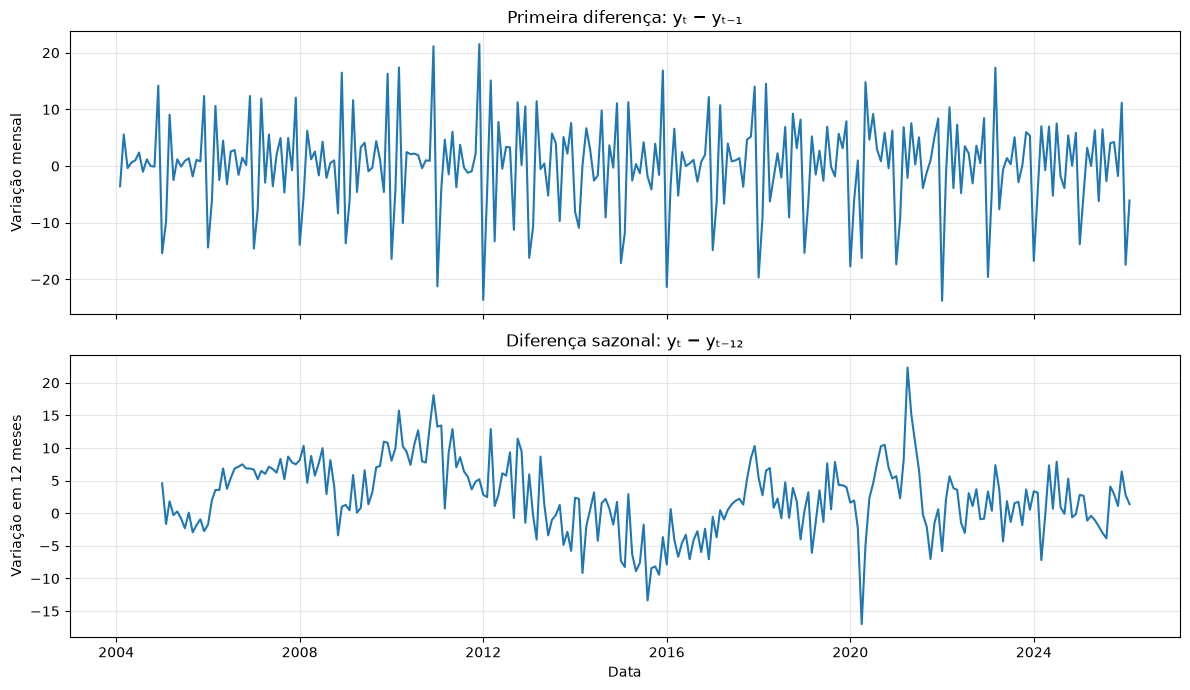

In [6]:
y = df_sf["y"]

y_diff_1 = y.diff()
y_diff_12 = y.diff(12)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(df_sf["ds"], y_diff_1)
axes[0].set_title("Primeira diferença: yₜ − yₜ₋₁")
axes[0].set_ylabel("Variação mensal")
axes[0].grid(True, alpha=0.3)

axes[1].plot(df_sf["ds"], y_diff_12)
axes[1].set_title("Diferença sazonal: yₜ − yₜ₋₁₂")
axes[1].set_ylabel("Variação em 12 meses")
axes[1].set_xlabel("Data")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
def testar_estacionariedade(serie, nome):
    serie = serie.dropna()

    adf_stat, adf_p, *_ = adfuller(serie, autolag="AIC")
    kpss_stat, kpss_p, *_ = kpss(
        serie,
        regression="c",
        nlags="auto"
    )

    return {
        "Série": nome,
        "ADF p-valor": adf_p,
        "KPSS p-valor": kpss_p
    }

resultados = pd.DataFrame([
    testar_estacionariedade(df_sf["y"], "Original"),
    testar_estacionariedade(y_diff_1, "Primeira diferença")
])

resultados.round(4)

C:\Users\Bárbara Reis Prado\AppData\Local\Temp\ipykernel_7156\2752873300.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, *_ = adfuller(serie, autolag="AIC")
C:\Users\Bárbara Reis Prado\AppData\Local\Temp\ipykernel_7156\2752873300.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_stat, kpss_p, *_ = kpss(
C:\Users\Bárbara Reis Prado\AppData\Local\Temp\ipykernel_7156\2752873300.py:5: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=Tru

,Série,ADF p-valor,KPSS p-valor
0,Original,0.3318,0.01
1,Primeira diferença,0.0054,0.10


**ADF e KPSS:** na série original, os testes indicam não estacionariedade. Após uma diferença regular, os resultados passam a ser compatíveis com estacionariedade. Assim, os testes sugerem uma diferença regular (`d = 1`); a escolha final será comparada com o AutoARIMA.

In [8]:
from pmdarima.arima.utils import ndiffs

d_adf = ndiffs(df_sf["y"], test="adf", alpha=0.05)
d_kpss = ndiffs(df_sf["y"], test="kpss", alpha=0.05)

print("ndiffs pelo ADF:", d_adf)
print("ndiffs pelo KPSS:", d_kpss)

ndiffs pelo ADF: 1
ndiffs pelo KPSS: 1


## 2. Modelagem

Os testes ADF, KPSS e `ndiffs` sugerem uma diferença regular (`d = 1`). Agora, o AutoARIMA buscará os componentes do SARIMA, considerando a sazonalidade mensal de 12 meses.

In [9]:
modelo = AutoARIMA(season_length=12)

sf = StatsForecast(
    models=[modelo],
    freq="MS",
    n_jobs=1
)

sf.fit(df_sf)

ajuste = sf.fitted_[0, 0]

arma = ajuste.model_["arma"]
p, q, P, Q, m, d, D = map(int, arma)

print(f"Modelo escolhido: SARIMA({p},{d},{q})({P},{D},{Q})[{m}]")
print(f"AICc: {ajuste.model_['aicc']:.2f}")

Modelo escolhido: SARIMA(3,1,2)(1,1,1)[12]
AICc: 1357.86


## 3. Diagnóstico dos resíduos

Os resíduos são as diferenças entre os valores observados e os estimados pelo modelo. Vamos verificar se apresentam algum padrão ao longo do tempo ou autocorrelação remanescente.

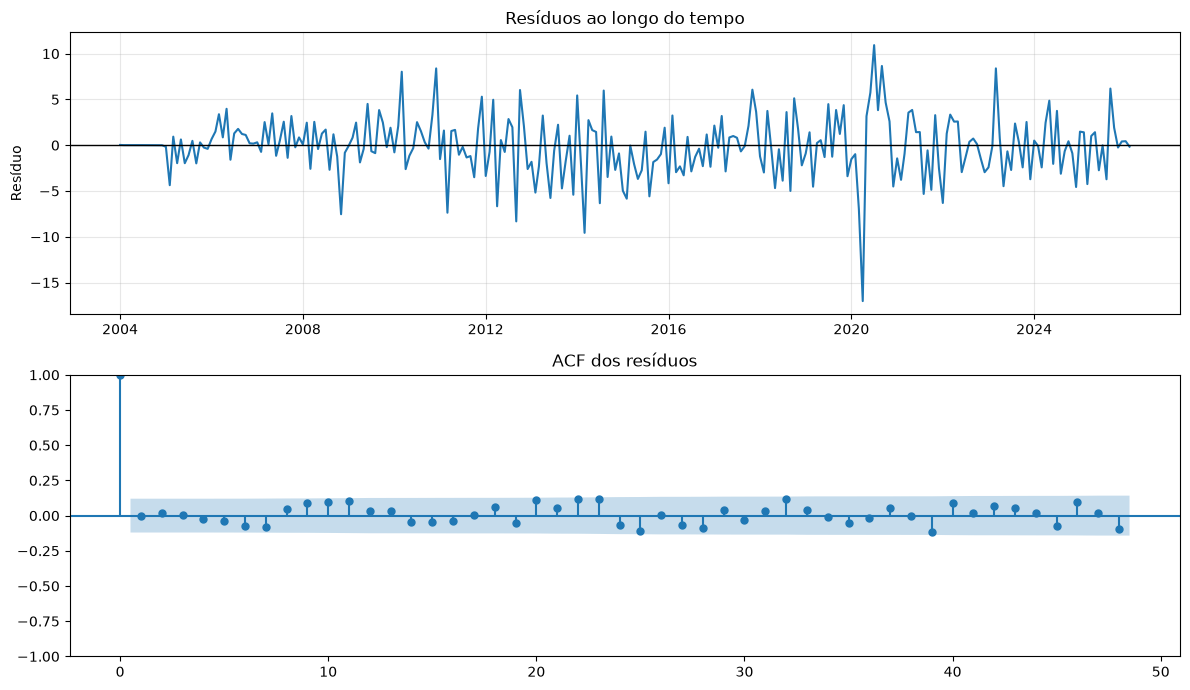

In [10]:
resid_array = np.asarray(ajuste.model_["residuals"])

n = min(len(resid_array), len(df_sf))
residuos = pd.Series(
    resid_array[-n:],
    index=df_sf["ds"].iloc[-n:]
)

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(residuos.index, residuos)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title("Resíduos ao longo do tempo")
axes[0].set_ylabel("Resíduo")
axes[0].grid(True, alpha=0.3)

plot_acf(residuos, lags=48, ax=axes[1])
axes[1].set_title("ACF dos resíduos")

plt.tight_layout()
plt.show()

**Choque em 2020:** os resíduos apresentam uma queda acentuada seguida de uma reação no período da pandemia. Esse padrão pode estar associado ao choque excepcional daquele período, que o modelo baseado nos padrões históricos não capturou integralmente.

In [11]:
from statsmodels.stats.diagnostic import acorr_ljungbox

graus_liberdade = sum(int(x) for x in ajuste.model_["arma"][:4])

ljung_box = acorr_ljungbox(
    residuos,
    lags=[12, 24],
    model_df=graus_liberdade,
    return_df=True
)

ljung_box.round(4)

,lb_stat,lb_pvalue
12,12.5331,0.0282
24,29.8693,0.0273


## 4. Previsão para os próximos 24 meses

O Ljung–Box indica autocorrelação remanescente nos resíduos. Ainda assim, vou gerar a previsão do AutoARIMA e considerar essa limitação na interpretação.

In [12]:
previsoes = sf.predict(h=24, level=[80, 95])

previsoes.head()

,unique_id,ds,AutoARIMA,AutoARIMA-lo-95,AutoARIMA-lo-80,AutoARIMA-hi-80,AutoARIMA-hi-95
0,Minas Gerais,2026-03-01,104.082317,97.462452,99.753820,108.410813,110.702181
1,Minas Gerais,2026-04-01,100.650095,93.175149,95.762490,105.537699,108.125040
2,Minas Gerais,2026-05-01,105.716517,97.868509,100.584980,110.848053,113.564524
3,Minas Gerais,2026-06-01,103.226496,94.594599,97.582402,108.870590,111.858394
4,Minas Gerais,2026-07-01,107.588234,98.658721,101.749540,113.426929,116.517747


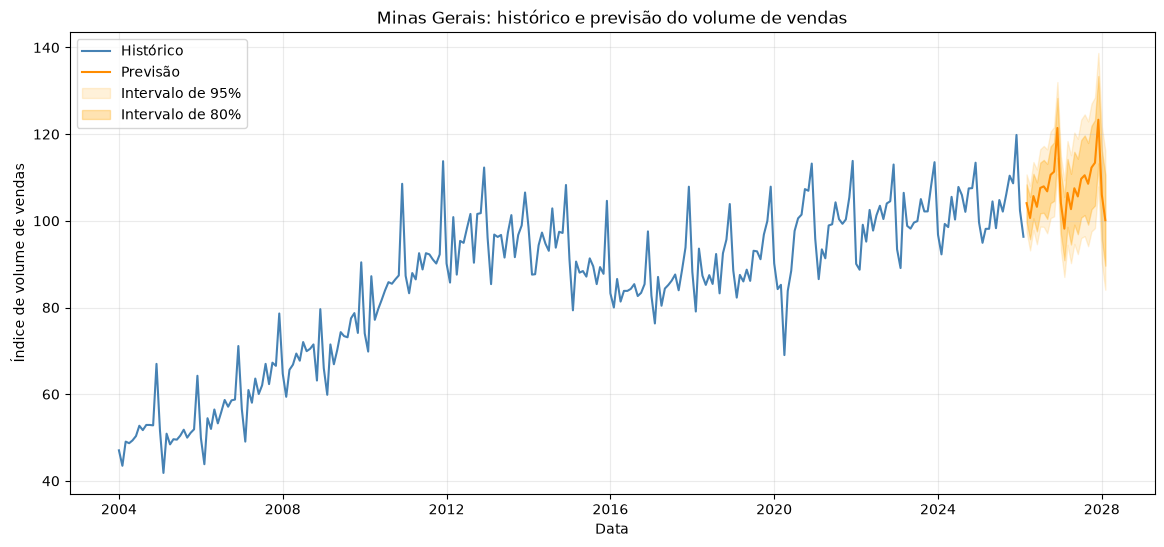

In [13]:
historico = df_sf.copy()
historico["ds"] = pd.to_datetime(historico["ds"])

prev = previsoes.copy()
prev["ds"] = pd.to_datetime(prev["ds"])

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(historico["ds"], historico["y"], label="Histórico", color="steelblue")
ax.plot(prev["ds"], prev["AutoARIMA"], label="Previsão", color="darkorange")

ax.fill_between(
    prev["ds"],
    prev["AutoARIMA-lo-95"],
    prev["AutoARIMA-hi-95"],
    color="orange",
    alpha=0.15,
    label="Intervalo de 95%",
)
ax.fill_between(
    prev["ds"],
    prev["AutoARIMA-lo-80"],
    prev["AutoARIMA-hi-80"],
    color="orange",
    alpha=0.30,
    label="Intervalo de 80%",
)

ax.set_title("Minas Gerais: histórico e previsão do volume de vendas")
ax.set_xlabel("Data")
ax.set_ylabel("Índice de volume de vendas")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

In [14]:
previsoes.tail()

,unique_id,ds,AutoARIMA,AutoARIMA-lo-95,AutoARIMA-lo-80,AutoARIMA-hi-80,AutoARIMA-hi-95
19,Minas Gerais,2027-10-01,112.289306,97.546199,102.649307,121.929306,127.032413
20,Minas Gerais,2027-11-01,113.403285,98.320553,103.541216,123.265354,128.486018
21,Minas Gerais,2027-12-01,123.328118,107.919196,113.252765,133.403471,138.737041
22,Minas Gerais,2028-01-01,106.014274,90.284509,95.729134,116.299414,121.744038
23,Minas Gerais,2028-02-01,100.139139,84.095244,89.648600,110.629677,116.183033


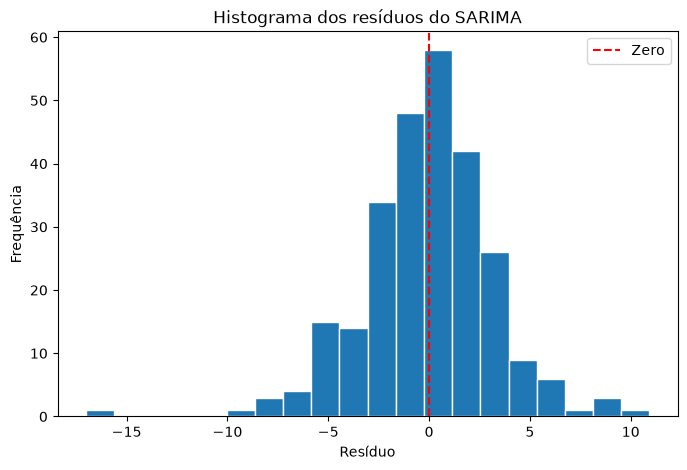

In [15]:
residuos_plot = pd.Series(residuos).dropna()

plt.figure(figsize=(8, 5))
plt.hist(residuos_plot, bins=20, edgecolor="white")
plt.axvline(0, color="red", linestyle="--", label="Zero")
plt.title("Histograma dos resíduos do SARIMA")
plt.xlabel("Resíduo")
plt.ylabel("Frequência")
plt.legend()
plt.show()

O histograma mostra que a maioria dos resíduos está concentrada perto de zero, embora existam alguns valores extremos, especialmente na cauda negativa. Esse gráfico descreve a distribuição dos resíduos, mas não é suficiente para concluir que sejam ruído branco.

## Discussão

1. **O ACF/PACF da série original sugeriu sazonalidade? E tendência? Bate com o que você viu no gráfico de linha?**  
   Sim. A ACF cai lentamente e apresenta um pico na defasagem 12, sugerindo tendência e sazonalidade anual, em linha com o gráfico de linha.

2. **Quantas diferenças (regular e sazonal) o AutoARIMA aplicou? E os componentes AR/MA? Conseguiu observar isso no ACF/PACF?**  
   O AutoARIMA escolheu SARIMA(3,1,2)(1,1,1)[12], com uma diferença regular e uma sazonal. O pico no lag 12 sugere sazonalidade, mas os componentes AR e MA não ficam claramente definidos pelos gráficos da série original.

3. **Os resíduos parecem white noise? Algum padrão remanescente sazonal?**  
   Os resíduos parecem variar em torno de zero, mas o Ljung–Box apresentou p-valores de 0,0282 e 0,0273 nos lags 12 e 24. Portanto, há evidência de autocorrelação remanescente.

4. **A previsão pareceu razoável visualmente? Captura a sazonalidade, fica bem ancorada no histórico e os intervalos abrem muito com o horizonte?**  
   A previsão mantém oscilações anuais e fica próxima do histórico recente. Os intervalos aumentam com o horizonte, mostrando maior incerteza. A queda observada em 2020 coincide com o período da pandemia, mas esta análise não permite atribuir causalidade.

5. **Que outras UFs você imagina que dariam um SARIMA bem diferente do seu, e por quê? Pense em estados de regiões diferentes, com perfil econômico distinto.**  
   O Amazonas poderia apresentar um SARIMA diferente por ter perfil econômico e composição do comércio distintos dos de Minas Gerais, o que pode gerar outros padrões de tendência e sazonalidade.